# Phase unwrapping with Kamui

This notebook unwraps synthetic 2-D phase images with Kamui's two grid solvers, the
network-programming ILP solved by LEMON and the PUMA graph cuts, and compares them with three
other unwrappers:

- scikit-image's `unwrap_phase`, the quality-guided path follower of Herráez et al. (2002);
- SNAPHU, the statistical-cost network-flow unwrapper of Chen and Zebker (2001), through
  [snaphu-py](https://github.com/isce-framework/snaphu-py);
- [spurs](https://github.com/scottstanie/spurs), the sparse-gradient ADMM unwrapper of Chartrand
  et al. (2019).

Along the way, it shows Kamui's per-pixel weights, missing data, and solver report.

Unwrapping recovers the phase only up to one constant multiple of $2\pi$. In each figure, the
first column holds the true phase and the wrapped input. Every other column is one method: on
top, its result with that constant removed, on the same gray scale as the truth; below, the
pixels it gets wrong, in black. Hatching marks NaN.

In [1]:
import io
import os
import warnings
from contextlib import contextmanager, redirect_stdout
from time import perf_counter

import matplotlib.pyplot as plt
import numpy as np
import snaphu
from skimage import color, data, exposure, img_as_float
from skimage.restoration import unwrap_phase

import kamui

# spurs prints a notice about GDAL on import, which it needs only to read files.
with redirect_stdout(io.StringIO()), warnings.catch_warnings():
    warnings.simplefilter("ignore", SyntaxWarning)
    import spurs

# Seeded, so re-executing the notebook reproduces its figures.
rng = np.random.default_rng(0)

Each method below takes the wrapped phase and returns the unwrapped phase:

- SNAPHU takes a complex interferogram, a coherence map and its number of looks. Where an example
  has no coherence, it gets a uniform 0.5. NaN pixels become its mask.
- spurs returns a smooth estimate that differs from the wrapped phase by more than whole periods.
  Rounding that difference to whole periods turns it into an unwrapping of the input.
- Kamui LEMON passes `solver="lemon"`, which raises an error rather than fall back to HiGHS.

In [2]:
@contextmanager
def quiet_stdout():
    """Silence SNAPHU, whose executable logs to the process's stdout."""
    saved = os.dup(1)
    with open(os.devnull, "w") as devnull:
        os.dup2(devnull.fileno(), 1)
    try:
        yield
    finally:
        os.dup2(saved, 1)
        os.close(saved)


def unwrap_snaphu(wrapped, coherence=None):
    """Unwrap with SNAPHU's smooth-surface cost, masking NaN pixels."""
    valid = ~np.isnan(wrapped)
    igram = np.where(valid, np.exp(1j * np.nan_to_num(wrapped)), 0).astype(np.complex64)
    corr = np.full(wrapped.shape, 0.5) if coherence is None else coherence
    with quiet_stdout():
        unwrapped, _ = snaphu.unwrap(
            igram, corr.astype(np.float32), nlooks=1, cost="smooth", mask=valid
        )
    return np.where(valid, unwrapped, np.nan)


def unwrap_spurs(wrapped):
    """Unwrap with spurs, then snap the result to the nearest congruent phase."""
    smooth = spurs.unwrap(wrapped).astype(float)
    return wrapped + 2 * np.pi * np.round((smooth - wrapped) / (2 * np.pi))


METHODS = {
    "skimage": unwrap_phase,
    "SNAPHU": unwrap_snaphu,
    "spurs": unwrap_spurs,
    "Kamui LEMON": lambda wrapped: kamui.unwrap_dimensional(wrapped, solver="lemon"),
    "Kamui PUMA": lambda wrapped: kamui.unwrap_dimensional(wrapped, method="gc"),
}


def unwrap_all(wrapped, methods=METHODS):
    """Run every method on `wrapped`."""
    return {name: unwrap(wrapped) for name, unwrap in methods.items()}

In [3]:
def common_offset(unwrapped, truth):
    """Return the most common whole number of periods between `unwrapped` and `truth`."""
    cycles = np.round((unwrapped - truth) / (2 * np.pi))
    values, counts = np.unique(cycles[~np.isnan(cycles)], return_counts=True)
    return values[counts.argmax()]


def cycle_errors(unwrapped, truth):
    """Whole periods by which each pixel misses `truth`, beyond the common offset."""
    return np.round((unwrapped - truth) / (2 * np.pi)) - common_offset(unwrapped, truth)


def n_errors(unwrapped, truth):
    """Count the pixels that land on the wrong multiple of 2π."""
    return int(np.sum(np.abs(cycle_errors(unwrapped, truth)) > 0.5))


def compare(truth, wrapped, results):
    """Plot each result above its wrong pixels, next to the true and wrapped phase."""
    ncols = 1 + len(results)
    height, width = truth.shape
    panel = 2.4
    fig, axes = plt.subplots(
        2,
        ncols,
        figsize=(panel * ncols, 2 * panel * height / width + 0.8),
        layout="constrained",
    )
    for ax in axes.flat:
        ax.set_xticks([])
        ax.set_yticks([])
        # NaN pixels are transparent, so the hatched background shows through.
        ax.patch.set_hatch("////")
        ax.patch.set_edgecolor("0.7")
    scale = {"cmap": "gray", "vmin": np.nanmin(truth), "vmax": np.nanmax(truth)}
    axes[0, 0].imshow(truth, **scale)
    axes[0, 0].set_title("True phase")
    axes[1, 0].imshow(wrapped, cmap="gray", vmin=-np.pi, vmax=np.pi)
    axes[1, 0].set_title("Wrapped")
    for (top, bottom), (name, unwrapped) in zip(axes[:, 1:].T, results.items(), strict=True):
        top.imshow(unwrapped - 2 * np.pi * common_offset(unwrapped, truth), **scale)
        top.set_title(name)
        errors = cycle_errors(unwrapped, truth)
        wrong = np.where(np.isnan(errors), np.nan, np.abs(errors) > 0.5)
        bottom.imshow(wrong, cmap="gray_r", vmin=0, vmax=1)
        bottom.set_title(f"{n_errors(unwrapped, truth)} wrong")
    plt.show()

## Plane wave

`kamui.wrap_difference` wraps a phase into $[-\pi, \pi)$, and `kamui.unwrap_dimensional`
unwraps a 2-D or 3-D array. Without noise, every method recovers the plane exactly.

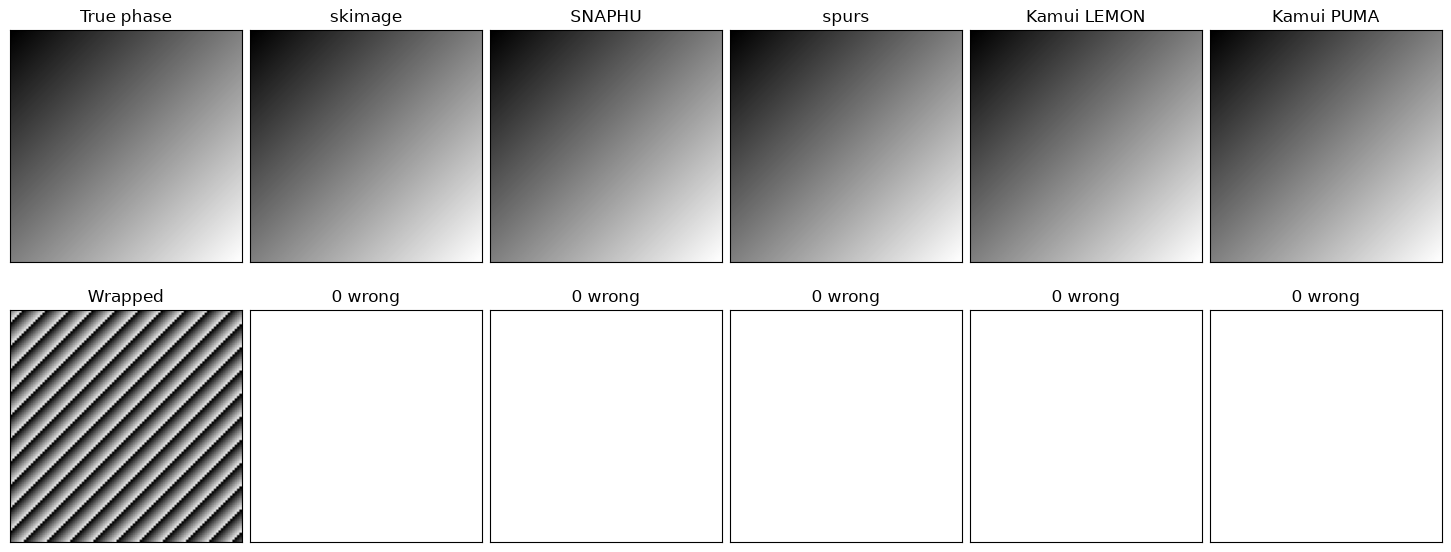

In [4]:
N = 100
yy, xx = np.mgrid[0:N, 0:N]
plane_wave = 0.2 * np.pi * (xx + yy)
wrapped_plane_wave = kamui.wrap_difference(plane_wave)
plane_results = unwrap_all(wrapped_plane_wave)

compare(plane_wave, wrapped_plane_wave, plane_results)

## Noise

Noise with a standard deviation of 0.15 periods creates residues: cycles of four pixels whose
wrapped differences do not sum to zero. Path following decides one pixel at a time, so one wrong
turn spreads into a patch. The other methods weigh the whole image at once, but cost it
differently. Kamui LEMON minimizes the number of $2\pi$ corrections, PUMA the L1 norm of the
unwrapped phase differences, and SNAPHU a statistical cost of them. On this noise, PUMA and
SNAPHU misplace the fewest pixels.

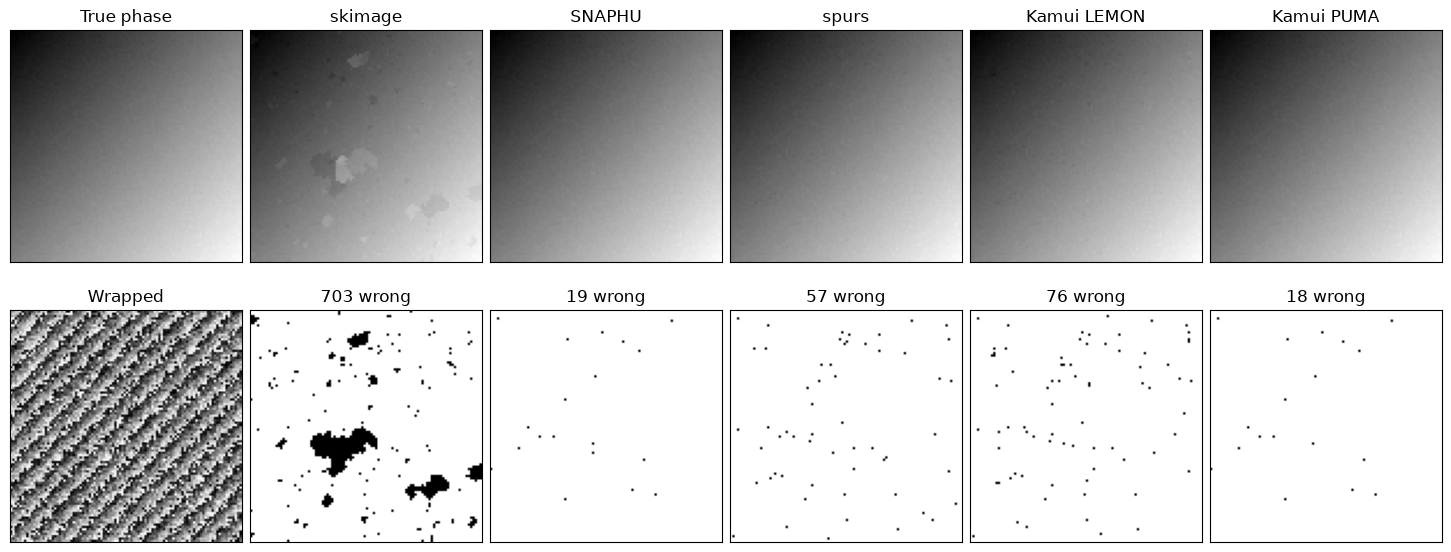

In [5]:
noisy_plane_wave = plane_wave + rng.normal(0, 0.15 * 2 * np.pi, plane_wave.shape)
wrapped_noisy_plane_wave = kamui.wrap_difference(noisy_plane_wave)

compare(noisy_plane_wave, wrapped_noisy_plane_wave, unwrap_all(wrapped_noisy_plane_wave))

## Shear

Two ramps meet head to head along the middle row, where the phase jumps by up to 60 rad. The jump
changes by less than $\pi$ from one column to the next, and Kamui LEMON recovers the seam exactly.
The other methods favour small phase differences over a 60 rad step, so they cut the image
elsewhere: skimage sets the halves apart, SNAPHU and PUMA split it into quadrants, and spurs
misplaces a strip along the seam.

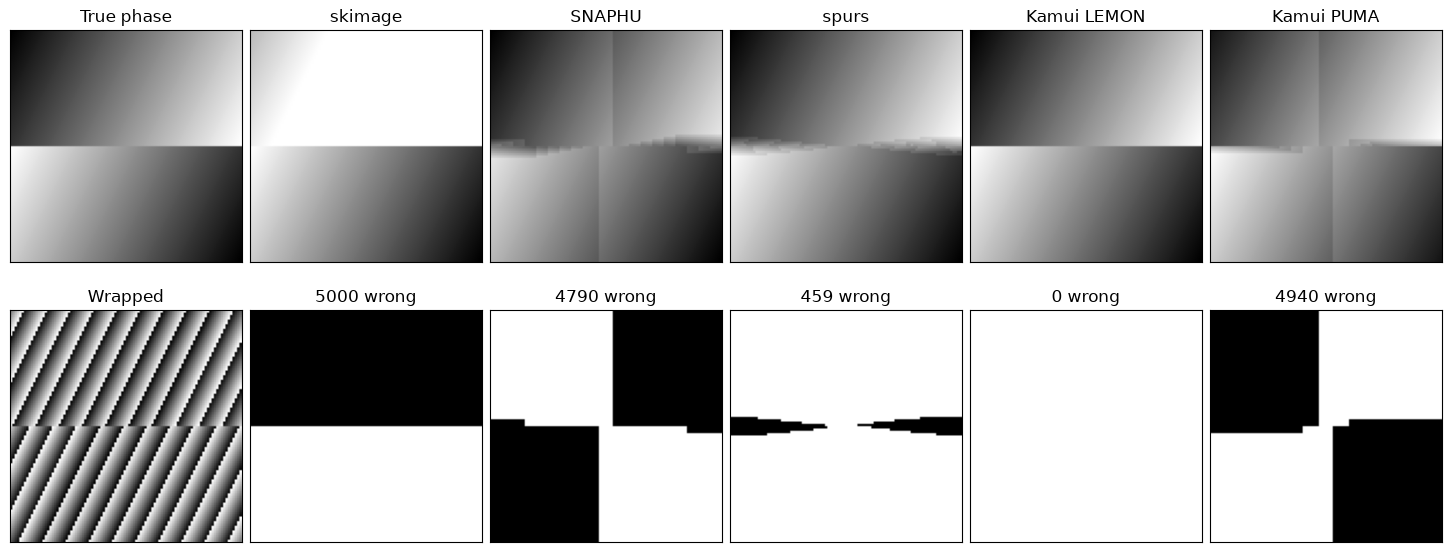

In [6]:
yy2, xx2 = np.mgrid[0:50, 0:100]
ramp = xx2 / 1.6 + yy2 / 3.2
shear = np.concatenate([ramp, ramp[::-1, ::-1]])
wrapped_shear = kamui.wrap_difference(shear)
shear_results = unwrap_all(wrapped_shear)

compare(shear, wrapped_shear, shear_results)

## Missing data

A Gaussian of height $10\pi$ with its top-left quadrant cut away has cliffs more than $\pi$ high
along the cut. Every method misplaces some pixels near them.

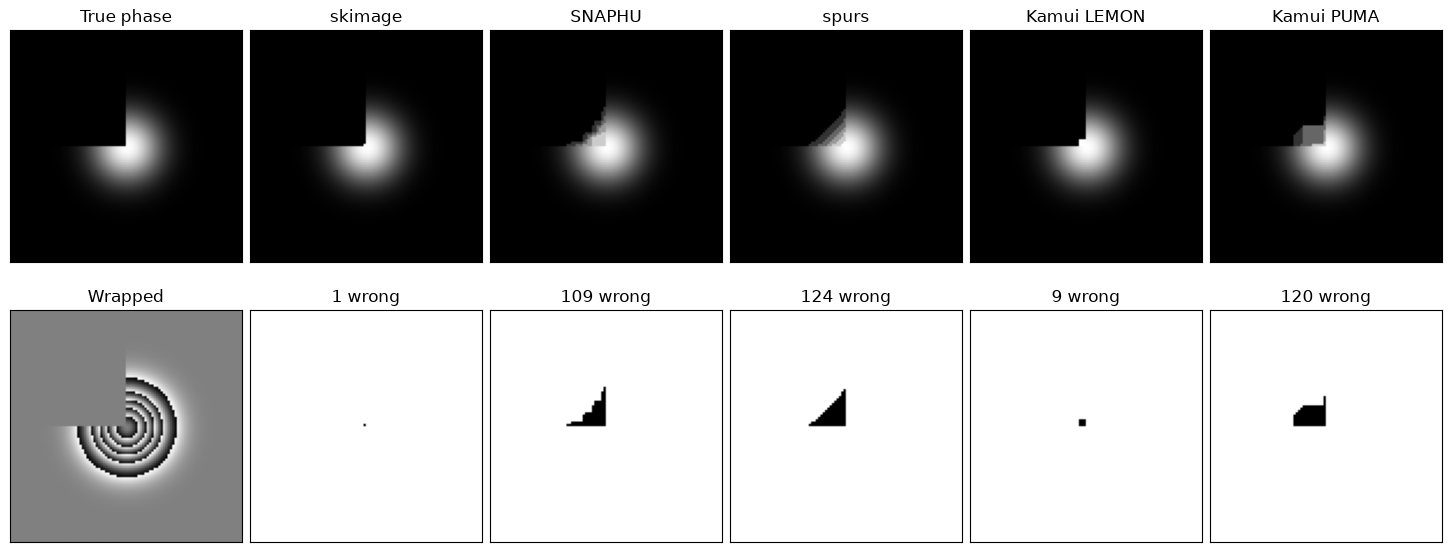

In [7]:
gauss = 10 * np.pi * np.exp(-0.5 * ((xx - N / 2) ** 2 + (yy - N / 2) ** 2) / (N / 10) ** 2)
gauss[: N // 2, : N // 2] = 0
wrapped_gauss = kamui.wrap_difference(gauss)

compare(gauss, wrapped_gauss, unwrap_all(wrapped_gauss))

When you know where the data is invalid, set it to NaN: `unwrap_dimensional` drops every edge that
touches a NaN pixel, unwraps the rest, and returns NaN there. SNAPHU takes the same pixels as a
mask. Masked like that, the remaining surface comes back exactly. skimage and spurs sit this one
out: spurs takes no mask, and skimage's `unwrap_phase` does not return on NaN input.

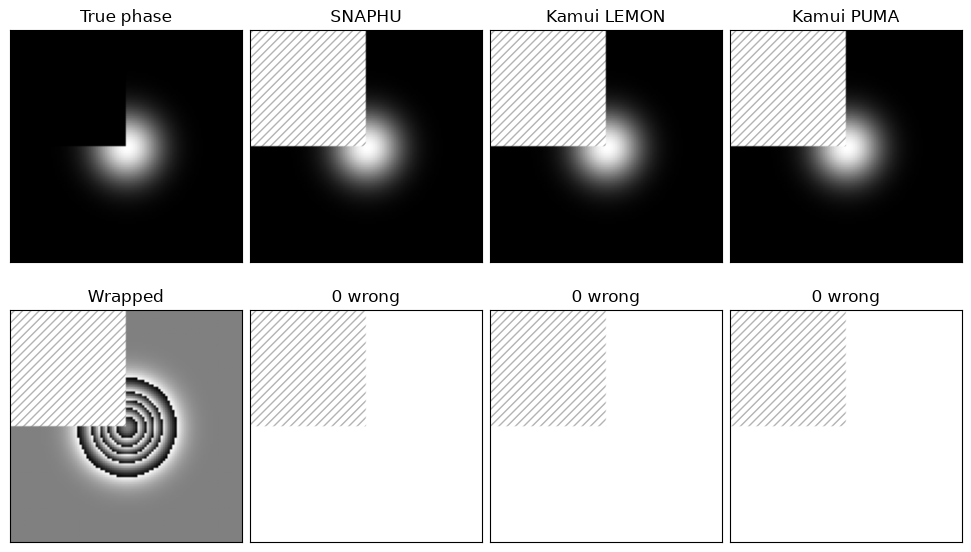

In [8]:
masked_gauss = wrapped_gauss.copy()
masked_gauss[: N // 2, : N // 2] = np.nan
masked_methods = {name: METHODS[name] for name in ("SNAPHU", "Kamui LEMON", "Kamui PUMA")}
masked_results = unwrap_all(masked_gauss, masked_methods)

compare(gauss, masked_gauss, masked_results)

## Weights

In practice, the noise varies across the image, and a quality map such as InSAR coherence says
where. Here a vertical band of low coherence crosses the plane wave. Kamui's per-pixel `weights`
make corrections cheap where coherence is low, which steers them into the band; each edge gets the
sum of its two pixels' weights. SNAPHU gets the coherence map itself.

LEMON's network simplex needs integer weights, and Kamui does not round them for you, so scale and
round them yourself. Fractional weights work too, but HiGHS solves them several times slower.
`return_info=True` also returns the solver's report, which names the solver that ran. PUMA takes
fractional weights as they are.

integer weights: lemon, fractional weights: highs


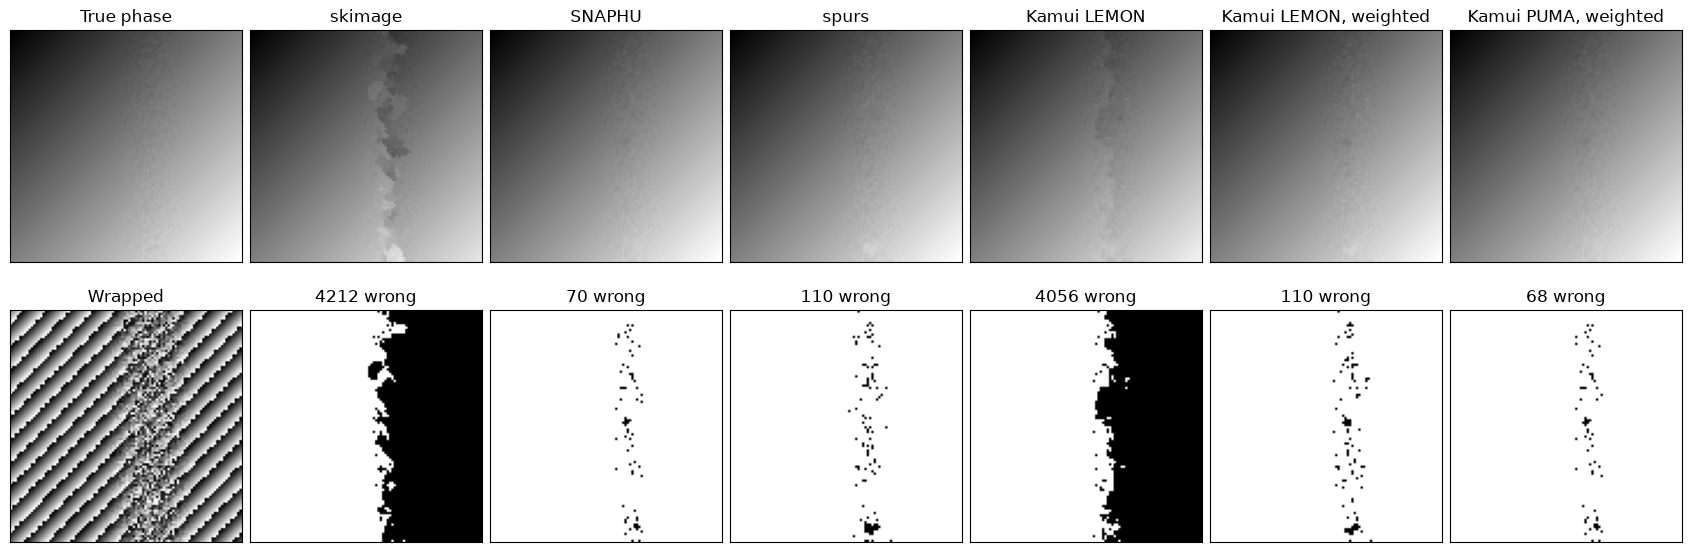

In [9]:
coherence = 1 - 0.85 * np.exp(-0.5 * ((xx - 60) / 8) ** 2)
noise_std = 0.25 * 2 * np.pi * (1 - coherence) / 0.85
weights = np.round(coherence * 100)


def banded(seed):
    """Draw the plane wave with noise that grows as coherence drops."""
    return plane_wave + np.random.default_rng(seed).normal(0, noise_std)


banded_wave = banded(1)
wrapped_banded_wave = kamui.wrap_difference(banded_wave)
unweighted = kamui.unwrap_dimensional(wrapped_banded_wave)
weighted, info = kamui.unwrap_dimensional(wrapped_banded_wave, weights=weights, return_info=True)
_, fractional_info = kamui.unwrap_dimensional(
    wrapped_banded_wave, weights=coherence, return_info=True
)
print(f"integer weights: {info.solver}, fractional weights: {fractional_info.solver}")

compare(
    banded_wave,
    wrapped_banded_wave,
    {
        "skimage": unwrap_phase(wrapped_banded_wave),
        "SNAPHU": unwrap_snaphu(wrapped_banded_wave, coherence),
        "spurs": unwrap_spurs(wrapped_banded_wave),
        "Kamui LEMON": unweighted,
        "Kamui LEMON, weighted": weighted,
        "Kamui PUMA, weighted": kamui.unwrap_dimensional(
            wrapped_banded_wave, method="gc", weights=coherence
        ),
    },
)

Most of the remaining errors sit inside the band. SNAPHU and spurs, whose costs grow with the
unwrapped phase differences, connect the two sides correctly without help. Kamui LEMON counts only
the corrections, and without weights some noise draws leave a whole side one period off. Over a
dozen draws:

In [10]:
wrong = {"Kamui LEMON": [], "Kamui LEMON, weighted": []}
for seed in range(1, 13):
    truth = banded(seed)
    wrapped = kamui.wrap_difference(truth)
    wrong["Kamui LEMON"].append(n_errors(kamui.unwrap_dimensional(wrapped), truth))
    wrong["Kamui LEMON, weighted"].append(
        n_errors(kamui.unwrap_dimensional(wrapped, weights=weights), truth)
    )

for name, counts in wrong.items():
    sides_off = sum(count > N * N / 4 for count in counts)
    print(f"{name}: {np.mean(counts):.0f} wrong pixels on average, a side off in {sides_off} of 12")

Kamui LEMON: 1115 wrong pixels on average, a side off in 3 of 12
Kamui LEMON, weighted: 429 wrong pixels on average, a side off in 1 of 12


## A photograph

The cat's fur is a harder test: neighbouring pixels differ by up to $2.25\pi$, so no unwrapper
recovers it exactly. At 300 × 451 pixels, it is also large enough for the timings to mean
something. PUMA needs `pip install kamui[extra]`.

skimage took 0.04 s
SNAPHU took 0.86 s
spurs took 0.07 s
Kamui LEMON took 0.23 s
Kamui PUMA took 0.97 s


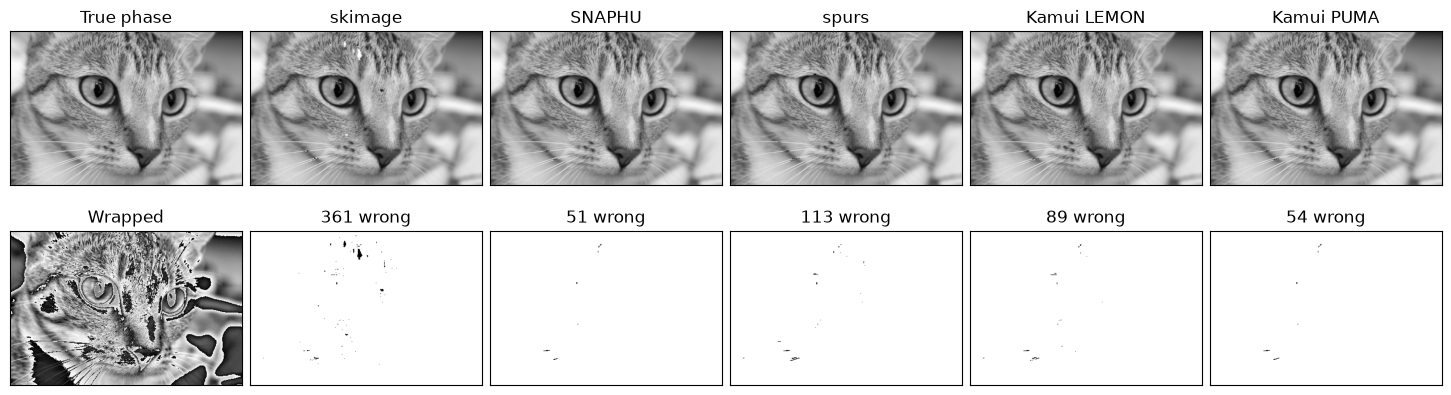

In [11]:
gray_cat = color.rgb2gray(img_as_float(data.chelsea()))
cat = exposure.rescale_intensity(gray_cat, out_range=(0, 4 * np.pi))
wrapped_cat = kamui.wrap_difference(cat)

cat_results = {}
for name, unwrap in METHODS.items():
    start = perf_counter()
    cat_results[name] = unwrap(wrapped_cat)
    print(f"{name} took {perf_counter() - start:.2f} s")

compare(cat, wrapped_cat, cat_results)

## Check

CI executes this notebook, so these asserts catch regressions. The noiseless plane must come back
exactly from every method, the shear only from Kamui LEMON, and the masked Gaussian from every
method that took the mask. Weights must halve Kamui LEMON's average error in the banded example,
and fewer than 1 % of the cat's pixels may land on the wrong multiple of $2\pi$ with either Kamui
solver.

In [12]:
for unwrapped in plane_results.values():
    assert n_errors(unwrapped, plane_wave) == 0
for name, unwrapped in shear_results.items():
    assert (n_errors(unwrapped, shear) == 0) == (name == "Kamui LEMON")
for unwrapped in masked_results.values():
    assert n_errors(unwrapped, gauss) == 0
    assert np.isnan(unwrapped[: N // 2, : N // 2]).all()
assert info.solver == "lemon" and fractional_info.solver == "highs"
assert np.mean(wrong["Kamui LEMON, weighted"]) < np.mean(wrong["Kamui LEMON"]) / 2
for name in ("Kamui LEMON", "Kamui PUMA"):
    assert n_errors(cat_results[name], cat) < 0.01 * cat.size